# ส่วนที่ 7 · ประเมินผลและเปรียบเทียบทุกโมเดล

**ผู้รับผิดชอบ:** คนที่ 7 · **ส่ง:** ตาราง ROUGE รวม + copy-rate + error analysis

**วิธีใช้:** วางไฟล์ `predictions_<ชื่อโมเดล>.csv` ของแต่ละคนไว้ในโฟลเดอร์ `predictions/` แล้ว Run all
- ไฟล์ต้องมีคอลัมน์ `summary` (เฉลย) และ `pred` (ที่โมเดลสรุป) · มี `body` จะได้คำนวณ copy-rate ด้วย
- Lead-3 คำนวณในนี้เองจาก `data/processed/test.jsonl` จึงรันได้แม้ยังไม่มีไฟล์ของใคร
- ROUGE ใช้ฟังก์ชันเดียวกับทุกคน (newmm tokenizer)

In [1]:
!pip -q install pythainlp python-crfsuite rouge_score pandas matplotlib


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import glob, json, os, re
import pandas as pd, numpy as np
from rouge_score import rouge_scorer
from pythainlp.tokenize import word_tokenize, sent_tokenize

TEST_JSONL = "../data/processed/test.jsonl" if os.path.exists("../data/processed/test.jsonl") else "data/processed/test.jsonl"
PRED_DIR   = "../predictions" if os.path.isdir("../predictions") else "predictions"
N_TEST = 500   # ใช้ 500 ข่าวแรกของ test กลาง ให้ทุกโมเดลวัดบนชุดเดียวกัน

class ThaiTokenizer:
    def tokenize(self, text):
        return [w for w in word_tokenize(text, engine="newmm") if w.strip()]
TOK = ThaiTokenizer()
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], tokenizer=TOK)

def thai_rouge(preds, refs):
    s = [scorer.score(r, p) for p, r in zip(preds, refs)]
    return {k: round(100 * np.mean([x[k].fmeasure for x in s]), 2) for k in ["rouge1", "rouge2", "rougeL"]}

## 1. ชุดทดสอบกลาง + Lead-3 (baseline)

In [3]:
test = pd.read_json(TEST_JSONL, lines=True).head(N_TEST)

def lead3(body):
    sents = []
    for line in body.splitlines():
        if line.strip(): sents += sent_tokenize(line.strip(), engine="crfcut")
    return "".join(sents[:3])

test["pred"] = test.body.map(lead3)
models = {"lead3": test[["id", "type", "body", "summary", "pred"]].copy()}
print(len(test), "ข่าว ·", test.type.value_counts().to_dict())

500 ข่าว · {'': 115, 'ข่าว,ทั่วไทย': 88, 'การเมือง': 26, 'สังคม': 24, 'ภูมิภาค': 19, 'บันเทิง,ข่าวบันเทิง': 16, 'ข่าว,การเมือง': 14, 'ข่าว,เศรษฐกิจ': 10, 'สิ่งแวดล้อม': 10, 'เศรษฐกิจ': 10, 'ข่าว,อาชญากรรม': 9, 'ต่างประเทศ': 7, 'ไลฟ์สไตล์,ผู้หญิง': 7, 'อาชญากรรม': 7, 'ข่าว,ต่างประเทศ': 6, 'กีฬา,ไทยรัฐเชียร์ไทยแลนด์': 6, 'ข่าว,สังคม': 6, 'เลือกตั้ง': 5, 'การเมือง,สิทธิมนุษยชน': 5, 'กีฬา': 4, 'ข่าว': 4, 'ศิลปะ-บันเทิง': 3, 'ภัยพิบัติ': 3, 'ไลฟ์สไตล์,ท่องเที่ยว': 3, 'การเมือง,ต่างประเทศ,สิทธิมนุษยชน': 2, 'การเมือง,ต่างประเทศ': 2, 'กีฬา,กีฬาอื่นๆ': 2, 'กีฬา,ฟุตบอลยุโรป': 2, 'วัฒนธรรม': 2, 'ข่าว,ยานยนต์': 2, 'สังคม,สิทธิมนุษยชน,คุณภาพชีวิต,ไอซีที': 1, 'การเมือง,สังคม,วัฒนธรรม': 1, 'การเมือง,เศรษฐกิจ,สังคม,การศึกษา,แรงงาน,คุณภาพชีวิต': 1, 'บันเทิง': 1, 'ต่างประเทศ,วัฒนธรรม,การศึกษา': 1, 'แรงงาน,คุณภาพชีวิต': 1, 'คุณภาพชีวิต,สิทธิมนุษยชน,สังคม': 1, 'การเมือง,การศึกษา,กีฬา': 1, 'การเมือง,สิทธิมนุษยชน,ความมั่นคง': 1, 'แรงงาน,สิทธิมนุษยชน,คุณภาพชีวิต,ต่างประเทศ': 1, 'วัฒนธรรม,สิทธิมนุษยชน,ต่างประ

## 2. โหลดผลของทุกโมเดล

In [4]:
for f in sorted(glob.glob(f"{PRED_DIR}/predictions_*.csv")):
    name = os.path.basename(f)[12:-4]
    df = pd.read_csv(f).dropna(subset=["summary", "pred"])
    on_shared = df.summary.isin(set(test.summary)).mean()
    print(f"{name:12s} {len(df):5d} แถว · ตรงกับ test กลาง {on_shared:.0%}")
    models[name] = df
print("โมเดลทั้งหมด:", list(models))

โมเดลทั้งหมด: ['lead3']


## 3. ตาราง ROUGE รวม
`same_test` = สัดส่วนข่าวที่ตรงกับ test กลาง ถ้าไม่ใช่ 100% แปลว่าวัดคนละชุด เทียบตรงๆ ไม่ได้ ต้องให้เจ้าของรันใหม่บน `test.jsonl`

In [5]:
def copy_rate(pred, body, n=2):
    # สัดส่วน n-gram ในบทสรุปที่ลอกมาจากตัวข่าวตรงๆ (1.0 = ลอกทั้งหมด)
    p, b = TOK.tokenize(pred), TOK.tokenize(body)
    g = lambda t: {tuple(t[i:i+n]) for i in range(len(t)-n+1)}
    gp = g(p)
    return len(gp & g(b)) / len(gp) if gp else np.nan

rows = []
for name, df in models.items():
    r = {"model": name, "n": len(df), "same_test": round(df.summary.isin(set(test.summary)).mean(), 2),
         **thai_rouge(df.pred, df.summary),
         "pred_words": round(df.pred.map(lambda s: len(TOK.tokenize(s))).mean(), 1)}
    if "body" in df: r["copy_rate_2g"] = round(np.nanmean([copy_rate(p, b) for p, b in zip(df.pred, df.body)]), 3)
    rows.append(r)
ref_copy = round(np.nanmean([copy_rate(s, b) for s, b in zip(test.summary, test.body)]), 3)
table = pd.DataFrame(rows).sort_values("rougeL", ascending=False).reset_index(drop=True)
print("copy-rate ของบทสรุปเฉลย (อ้างอิง):", ref_copy)
table

copy-rate ของบทสรุปเฉลย (อ้างอิง): 0.49


,model,n,same_test,rouge1,rouge2,rougeL,pred_words,copy_rate_2g
0,lead3,500,1.0,26.94,18.4,23.66,40.8,1.0


## 4. Error analysis
ROUGE-L รายข่าว แยกตามหมวด และ 5 ข่าวที่แย่ที่สุดของแต่ละโมเดล

In [6]:
for name, df in models.items():
    df["rougeL"] = [scorer.score(r, p)["rougeL"].fmeasure for p, r in zip(df.pred, df.summary)]
    if "type" in df:
        cat = df.type.fillna("").str.split(",").str[0].replace("", "(ไม่ระบุ)")
        print(name, df.groupby(cat).rougeL.agg(["mean", "count"]).query("count >= 5").round(3).sort_values("mean").to_dict("index"))
pd.set_option("display.max_colwidth", 150)
worst = {n: d.nsmallest(5, "rougeL")[["summary", "pred", "rougeL"]] for n, d in models.items()}
worst["lead3"]

lead3 {'สังคม': {'mean': 0.146, 'count': 31}, 'อาชญากรรม': {'mean': 0.16, 'count': 7}, 'เศรษฐกิจ': {'mean': 0.17, 'count': 13}, 'ไลฟ์สไตล์': {'mean': 0.184, 'count': 12}, 'ภูมิภาค': {'mean': 0.197, 'count': 19}, 'ข่าว': {'mean': 0.205, 'count': 140}, 'ต่างประเทศ': {'mean': 0.206, 'count': 15}, 'เลือกตั้ง': {'mean': 0.219, 'count': 5}, '(ไม่ระบุ)': {'mean': 0.221, 'count': 115}, 'คุณภาพชีวิต': {'mean': 0.226, 'count': 14}, 'กีฬา': {'mean': 0.243, 'count': 16}, 'การเมือง': {'mean': 0.31, 'count': 59}, 'สิ่งแวดล้อม': {'mean': 0.326, 'count': 10}, 'วัฒนธรรม': {'mean': 0.359, 'count': 8}, 'บันเทิง': {'mean': 0.455, 'count': 17}, 'สิทธิมนุษยชน': {'mean': 0.518, 'count': 5}}


,summary,pred,rougeL
18,กองปราบร่วมลุย บุกค้นบ้านเสี่ยตงที่เมืองกาญจน์ อายัดเสือโคร่งพันธุ์เบงกอล 4 ตัว เชื่อเชื่อมโยงวัดเสือ หรืออาจเป็นที่ชำแหละ ด้าน ส.ป.ก.ติดป้ายยึดที...,เมื่อเวลา 10.00 น. วันที่ 7 มิ.ย. 59 พ.ต.อ.,0.0
25,ชาวบ้านสุดทน! แจ้งจับพระเมาอาละวาด กลางศาลาวัดหนองยาว อ.พนมสารคาม หลังส่งเสียงดัง อ้างเป็นโรคร้ายประจำตัว ต้องซดเหล้าดับพิษ แต่ตำรวจไม่ฟัง หิ้วเข้...,เมื่อเวลา 19.00 น. วันที่ 27 พ.ย.,0.0
26,สุนัขผู้ซื่อสัตย์ เฝ้าศพนายหญิงไม่ห่าง เป็นลมเสียชีวิตในสวนกล้วยหลังบ้าน หลานชายหาป้าไม่เจอ 3 วัน แจ้งคนหาย จนได้ยินเสียงเห่าลั่น ถึงกับช็อกเห็น เ...,เมื่อวันที่ 12 พ.ย. ร.ต.อ.,0.0
27,มาเรียมไม่ตายฟรี แถลงข่าวเปิดตัวกิจกรรม พายเรือเพื่อเจ้าพระยา : เก็บขยะจากปากน้ำโพถึงอ่าวไทย ปี 2 ระยะทาง 349.5 กม. เริ่ม 1 ต.ค. นี้ ปริญญา มธ. เช...,วันนี้ (6 ก.ย.2562) ที่ ม.ธรรมศาสตร์ ท่าพระจันทร์,0.0
54,ทหาร ฉก.ม.3 กกล.ผาเมือง ตั้งด่านตรวจพบ 2โจ๋ซิ่ง จยย.มีพิรุธ แต่กลับรีบวิ่งหลบหนี จนท.จึงรีบตามตะครุบตัวได้มา 1 คน อีกคนอาศัยความมืดหลบหนีไปได้ ตรว...,เมื่อเวลา 22.30 น. วันที่ 07 ก.ค.60 พ.อ.,0.0


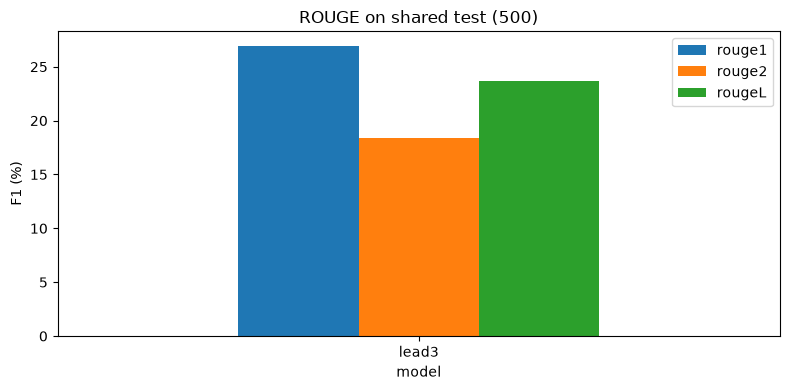

In [7]:
import matplotlib.pyplot as plt
ax = table.set_index("model")[["rouge1", "rouge2", "rougeL"]].plot.bar(figsize=(8, 4), rot=0)
ax.set_ylabel("F1 (%)"); ax.set_title("ROUGE on shared test (500)"); plt.tight_layout()
os.makedirs("../reports" if os.path.isdir("../reports") else "reports", exist_ok=True)
out = "../reports" if os.path.isdir("../reports") else "reports"
plt.savefig(f"{out}/rouge_compare.png", dpi=150)
table.to_csv(f"{out}/rouge_table.csv", index=False)

## 5. สรุป (ให้คนที่ 7 เขียนต่อ)
- โมเดลไหนดีที่สุด และชนะ Lead-3 ไหม
- copy-rate ของแต่ละโมเดลเทียบกับเฉลย บอกอะไร (ThaiSum ลอกประโยคต้นข่าว → Lead-3 แข็งมาก)
- หมวดข่าวไหนสรุปยาก ยกตัวอย่างจากตารางข้อ 4